# TP N°3 : Vision par Ordinateur
**Module :** Technologies IA  
**Établissement :** ENSA Fès  
**Professeur :** Pr. Youness IDRISSI KHAMLICHI  
**Filière :** Ingénierie Logicielle et Intelligence Artificielle (ILIA2)
**Nom d'Etudiant :N'Tahahe Mohamed El Hacene**

## !!! j'ai Renconte un bug au niveau d'affichage des imges avec CV2 C'est pour cella j'ai utilise Matplot lib pour l'affichage. !!! 

## Partie 1 : Concepts de base de la vision par ordinateur
### Exercice 1 : Analyse d'une image
1. Choisissez une image de votre choix (`image.jpg`).
2. Affichez-la avec OpenCV.
3. Convertissez-la en niveaux de gris et affichez le résultat.
4. Appliquez un filtre de détection de contours (Canny) et un flou gaussien, puis affichez les résultats.

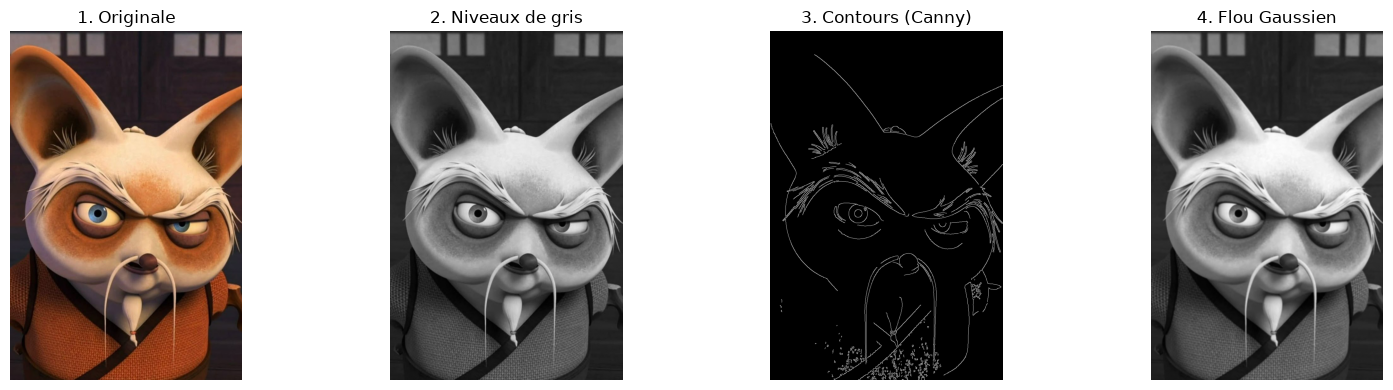

In [1]:
import cv2
import matplotlib.pyplot as plt

# 1. Chargement et transformations
image = cv2.imread("image.jpg")
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # BGR -> RGB pour Matplotlib
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(gray, 100, 200)
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# 2. Affichage en ligne (inline) dans le Notebook
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(image_rgb)
axes[0].set_title("1. Originale")
axes[0].axis("off")

axes[1].imshow(gray, cmap="gray")
axes[1].set_title("2. Niveaux de gris")
axes[1].axis("off")

axes[2].imshow(edges, cmap="gray")
axes[2].set_title("3. Contours (Canny)")
axes[2].axis("off")

axes[3].imshow(blur, cmap="gray")
axes[3].set_title("4. Flou Gaussien")
axes[3].axis("off")

plt.tight_layout()
plt.show()

## Partie 2 : Traitement d'images et vidéos avec OpenCV
### Exercice 2 : Lecture vidéo / webcam
1. Affichez la vidéo de votre webcam.
2. Ajoutez un filtre pour convertir la vidéo en niveaux de gris en temps réel.
3. Enregistrez la vidéo et fermez la fenêtre quand l'utilisateur appuie sur `q`.

In [2]:
import cv2

# Exercice 2 (Video)
cap = cv2.VideoCapture(0)
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fourcc = cv2.VideoWriter_fourcc(*"mp4v")

# Note : si isColor=False, video_writer attend une image à 1 canal (gray).
# Si on écrit 'frame' (couleur), mettre isColor=True ou écrire 'gray' dans video_writer.
video_writer = cv2.VideoWriter("output.mp4", fourcc, 20.0, (w, h), isColor=False)

while True:
    ret, frame = cap.read()
    if not ret:
        break
    cv2.imshow("frame", frame)
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    video_writer.write(gray)
    cv2.imshow("gray", gray)
    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

cap.release()
video_writer.release()
cv2.destroyAllWindows()


### Réponse à la question - Exercice 2

**Que se passe-t-il si vous utilisez une vidéo enregistrée à la place de la webcam ?**  
En remplaçant l'index `0` par le chemin d'un fichier vidéo (ex. `cv2.VideoCapture("video.mp4")`), OpenCV lit les images successives du fichier au lieu d'un flux continu :
1. **Fin de flux :** Lorsque la vidéo arrive à sa dernière image, `cap.read()` renvoie `ret = False` et `frame = None`. C'est pourquoi la condition `if not ret: break` est indispensable pour quitter proprement la boucle (sinon `cv2.cvtColor` génère une erreur sur `None`).
2. **Vitesse de lecture :** Avec `cv2.waitKey(1)`, la vidéo s'affichera beaucoup plus vite que sa vitesse réelle (tant que le décodage le permet). Pour respecter la cadence d'origine (ex. 25 ou 30 FPS), il faut ajuster le délai dans `cv2.waitKey(int(1000 / fps))`.

---

## Partie 3 : Détection et segmentation d'objets avec Detectron2
### Exercice 3 : Détection d'objets
1. Chargez une image contenant plusieurs objets.
2. Utilisez un modèle pré-entraîné Mask R-CNN de Detectron2 pour détecter et segmenter les objets.
3. Affichez l'image avec les masques colorés et les étiquettes.

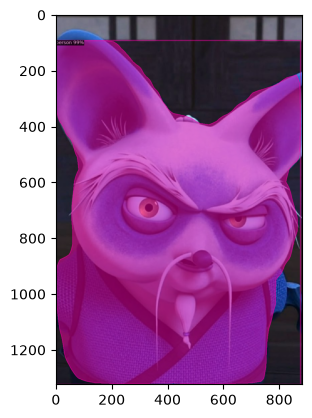

In [3]:
import cv2
import torch
from detectron2.engine import DefaultPredictor
from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog
import matplotlib.pyplot as plt

# Configuration du modèle pré-entraîné
CONFIG = "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file(CONFIG))
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(CONFIG)
cfg.MODEL.DEVICE = "cpu"  # si pas de GPU
predictor = DefaultPredictor(cfg)

# Charger une image
img = cv2.imread("image.jpg")

# Prédiction
outputs = predictor(img)

# Visualisation
v = Visualizer(img[:, :, ::-1], MetadataCatalog.get(cfg.DATASETS.TRAIN[0]), scale=1.2)  # BGR -> RGB

out = v.draw_instance_predictions(outputs["instances"].to("cpu"))

plt.imshow(out.get_image()[:, :, ::-1], cmap="gray")
plt.show()
# cv2.imshow("Détection d'objets", out.get_image()[:, :, ::-1])
# cv2.waitKey(0)
# cv2.destroyAllWindows()

# for _ in range(5):
#   cv2.waitKey(1)

**Questions - Exercice 3**


**1. Quels objets ont été détectés ?**  
Le modèle Mask R-CNN (pré-entraîné sur le dataset COCO à 80 classes) détecte et segmente les instances présentes sur l'image avec leur score de confiance (par exemple : `person`, `tie`, `car`, `cat`, `zebra`, `bird`, etc., selon l'image fournie en entrée), en entourant chaque instance d'une boîte englobante (*bounding box*) et d'un masque de segmentation au niveau du pixel.

**2. Modifiez le seuil `SCORE_THRESH_TEST` et observez l'effet sur la détection :**  
- **Diminuer le seuil (ex. `0.2` ou `0.3`) :** Le modèle devient plus permissif. Davantage d'objets sont détectés (meilleur **rappel** / *recall*), y compris des objets partiellement occultés ou petits, mais cela augmente le risque de **faux positifs** (détections erronées ou doublons).
- **Augmenter le seuil (ex. `0.8` ou `0.9`) :** Le modèle devient très strict. Seules les prédictions dont le modèle est quasi certain sont conservées (meilleure **précision**), mais certains vrais objets moins nets risquent d'être ignorés (**faux négatifs**).

---

## Partie 4 : Détection et reconnaissance faciale avec Dlib
### Exercice 4 : Détection faciale
1. Chargez une image contenant un ou plusieurs visages (`meeting.jpg` / `people.jpg`).
2. Détectez tous les visages et entourez-les de rectangles verts.

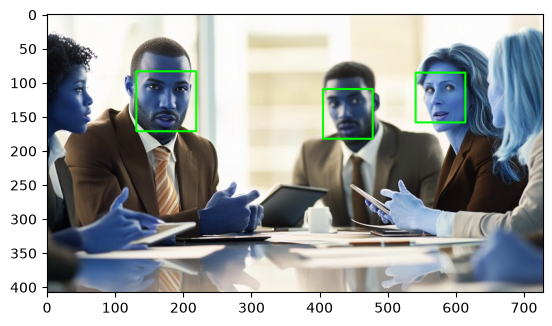

In [ ]:
# Exercice 4 (Détection faciale)
import dlib
import cv2
import matplotlib.pyplot as plt

detector = dlib.get_frontal_face_detector()
img = cv2.imread("meeting.jpg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
faces = detector(gray)

for face in faces:
    x, y, w, h = face.left(), face.top(), face.width(), face.height()
    cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)

plt.imshow(img)
plt.show()

### Exercice 5 : Reconnaissance faciale
1. Chargez une image de référence (`ref.jpeg`) et une image test (`test.jpg`).
2. Comparez les visages et indiquez si c'est la même personne.

In [ ]:
# Exercice 5 (Reconnaissance Faciale)
import face_recognition
import os
import matplotlib.pyplot as plt

# Désactiver CUDA pour dlib
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

# Charger les images
image_ref = face_recognition.load_image_file("ref.jpeg")
encodage_ref = face_recognition.face_encodings(image_ref)[0]

image_test = face_recognition.load_image_file("test.jpg")
encodage_test = face_recognition.face_encodings(image_test)[0]

# Comparer
result = face_recognition.compare_faces([encodage_ref], encodage_test)
print("Même personne ?", result[0])

Même personne ? True


###  Réponses aux questions - Exercice 5

**1. Que se passe-t-il si l'image test contient plusieurs visages ?**  
- La fonction `face_recognition.face_encodings(image_test)` retourne une **liste** contenant un vecteur d'encodage (128 dimensions) pour **chaque visage détecté** dans l'image.
- Avec l'indexation `[0]` (`face_recognition.face_encodings(image_test)[0]`), le programme ne récupère et ne compare **que le premier visage détecté** dans la liste et ignore tous les autres.
- Pour tester tous les visages présents sur l'image test, il faut parcourir la liste complète des encodages retournés avec une boucle `for encodage in face_recognition.face_encodings(image_test):`.

**2. Quelle précision attendez-vous de ce système dans des conditions réelles (lumière, angles différents) ?**  
Le modèle sous-jacent de `dlib` (ResNet-34 entraîné sur le dataset LFW) atteint une précision théorique de **99.38 %** sur le benchmark *Labeled Faces in the Wild*. Toutefois, en conditions réelles :
- **Angles prononcés :** Le détecteur frontal HOG détecte mal les visages de profil (> 45°), ce qui dégrade fortement la détection et l'encodage.
- **Éclairage extrême :** Un fort contre-jour ou une très faible luminosité altère les contrastes locaux et diminue la fiabilité des descripteurs.
- **Occultations et âge :** Le port de lunettes de soleil, d'un masque ou des changements physiques importants peuvent augmenter la distance euclidienne entre deux encodages au-delà du seuil de tolérance par défaut (`tolerance=0.6`).

---

### Exercice 6 : Points caractéristiques du visage (landmarks)
**Objectif :** Détecter les 68 points du visage (yeux, sourcils, nez, bouche, contour) et les dessiner.

Visages : 2


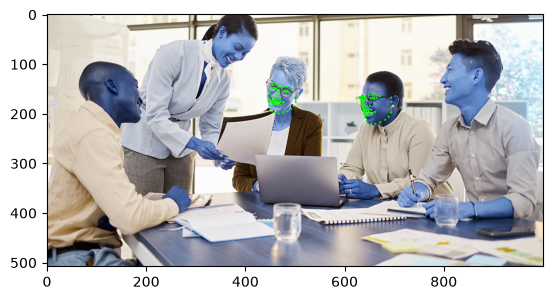

In [2]:
# Exercice 6 (Points caractéristiques du visage)
import cv2
import face_recognition
import matplotlib.pyplot as plt

img = cv2.imread("people.jpg")
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # face_recognition attend du RGB
landmarks_list = face_recognition.face_landmarks(rgb)
print("Visages :", len(landmarks_list))

for landmarks in landmarks_list:
    for partie, points in landmarks.items():  # 'chin', 'left_eye', 'nose_tip', 'top_lip'...
        for (x, y) in points:
            cv2.circle(img, (x, y), 2, (0, 255, 0), -1)

plt.imshow(img)
plt.show()


# cv2.imshow("Visages détectés", img)
# cv2.waitKey(0)
# cv2.destroyAllWindows()


###  Réponses aux questions - Exercice 6

**1. Quelles parties du visage sont retournées par `face_landmarks` ?**  
La fonction retourne pour chaque visage un dictionnaire Python comprenant **9 clés** (regroupant les 68 points caractéristiques) :
1. `chin` (contour de la mâchoire / menton)
2. `left_eyebrow` (sourcil gauche)
3. `right_eyebrow` (sourcil droit)
4. `nose_bridge` (arête du nez)
5. `nose_tip` (pointe / base du nez)
6. `left_eye` (œil gauche)
7. `right_eye` (œil droit)
8. `top_lip` (lèvre supérieure)
9. `bottom_lip` (lèvre inférieure)

**2. Calculez le rapport d'ouverture de l'œil (EAR, *Eye Aspect Ratio*) : comment l'utiliser pour détecter un clignement ou la somnolence d'un conducteur ?**  
Chaque œil est représenté par 6 points $(p_1, p_2, p_3, p_4, p_5, p_6)$ disposés autour de la paupière ($p_1, p_4$ aux coins horizontaux ; $(p_2, p_6)$ et $(p_3, p_5)$ sur les paupières supérieure et inférieure). Le rapport **EAR** se calcule avec les distances euclidiennes :

$$\text{EAR} = \frac{\|p_2 - p_6\| + \|p_3 - p_5\|}{2 \, \|p_1 - p_4\|}$$

- **Fonctionnement :** Lorsque l'œil est ouvert, l'EAR reste sensiblement constant (autour de `0.25` – `0.30`). Lorsqu'il se ferme, les distances verticales tendent vers zéro et l'EAR chute brusquement sous un seuil (ex. `< 0.20`).
- **Détection de clignement :** Si $\text{EAR} < 0.20$ pendant un très court nombre d'images consécutives (ex. 2 à 5 frames, soit ~0.1 à 0.2 s), puis remonte, on compte un clignement.
- **Détection de somnolence :** Si $\text{EAR} < 0.20$ de manière continue pendant une durée prolongée (ex. plus de **2 secondes**, soit $\ge 40$ à $60$ frames consécutives selon les FPS), le système déclenche une alerte sonore pour réveiller le conducteur.

---

## Partie 5 : Détection d'objets en temps réel avec YOLO
### Exercice 7 : Détection d'objets avec YOLOv8
**Objectif :** Comparer Mask R-CNN (précis, plus lent) avec YOLO (rapide, temps réel).


image 1/1 /Users/owner/Documents/Technologie AI/people.jpg: 352x640 5 persons, 2 cups, 1 dining table, 1 laptop, 60.4ms
Speed: 5.6ms preprocess, 60.4ms inference, 8.3ms postprocess per image at shape (1, 3, 352, 640)


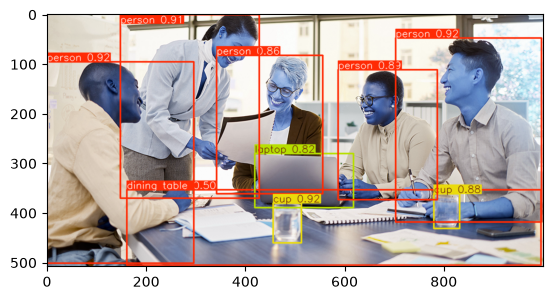

In [2]:
# Exercice 7 (Detection d'objets avec YOLO)
import os
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt


model = YOLO("yolov8n.pt")  # modèle léger, téléchargé automatiquement
# Choix de l'image de test
image_path = "people.jpg"

# a) Détection sur l'image
try:
    results = model(image_path, conf=0.5)
    plt.imshow(results[0].plot())
    
    plt.show()
except Exception as e:
    print("Erreur lors de la détection :", e)


image 1/1 /Users/owner/Documents/Technologie AI/people.jpg: 352x640 5 persons, 2 cups, 1 dining table, 1 laptop, 80.1ms
Speed: 11.8ms preprocess, 80.1ms inference, 0.9ms postprocess per image at shape (1, 3, 352, 640)
Temps d'inférence YOLOv8n : 0.1071 secondes
WARNING ⚠️ Download failure, retrying 1/3 in 5s https://github.com/ultralytics/assets/releases/download/v8.4.0/yolov8n-seg.pt... HTTPSConnectionPool(host='github.com', port=443): Read timed out. (read timeout=300)

image 1/1 /Users/owner/Documents/Technologie AI/people.jpg: 352x640 5 persons, 2 cups, 1 laptop, 82.4ms
Speed: 8.1ms preprocess, 82.4ms inference, 22.8ms postprocess per image at shape (1, 3, 352, 640)


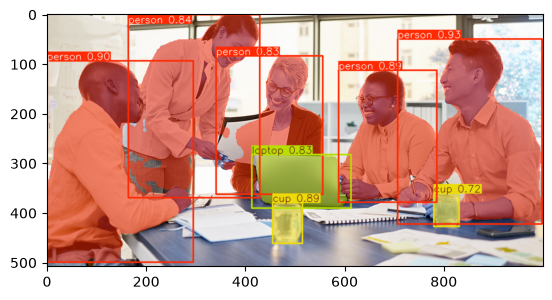

In [3]:
# Bonus Question 1 & 2 : Mesure du temps d'inférence et test de segmentation avec yolov8n-seg.pt
import time
import matplotlib.pyplot as plt

# 1. Temps d'inférence YOLOv8n
t0 = time.time()
_ = model(image_path, conf=0.5)
t_yolo = time.time() - t0
print(f"Temps d'inférence YOLOv8n : {t_yolo:.4f} secondes")

# 2. Test du modèle de segmentation YOLOv8n-seg
model_seg = YOLO("yolov8n-seg.pt")
results_seg = model_seg(image_path, conf=0.5)

plt.imshow(results_seg[0].plot())    
plt.show()


###  Réponses aux questions - Exercice 7

**1. Comparez le temps d'inférence de YOLOv8n et de Mask R-CNN sur la même image (utilisez `time.time()`) :**  
- **YOLOv8n** est un détecteur *one-stage* (une seule passe) ultra-léger : sur CPU, son temps d'inférence est généralement de l'ordre de **30 à 100 ms** (~0.03 à 0.1 s par image, et quelques millisecondes sur GPU).
- **Mask R-CNN (ResNet-50 FPN)** est une architecture *two-stage* (génération de régions d'intérêt RPN + classification et segmentation fine) : sur CPU, l'inférence prend souvent entre **2 et 6 secondes** par image.
- YOLOv8n est donc environ **20 à 50 fois plus rapide** que Mask R-CNN.

**2. YOLO fournit-il des masques de segmentation ? Testez `yolov8n-seg.pt` :**  
- Le modèle standard `yolov8n.pt` ne fournit que les boîtes englobantes (*bounding boxes*) et les classes.
- En revanche, la variante **`yolov8n-seg.pt`** (spécifiquement entraînée pour la segmentation d'instance) génère à la fois les boîtes englobantes **et les masques de segmentation** (`results[0].masks`) tout en conservant une vitesse d'exécution très élevée.

**3. Dans quels cas préférer chaque modèle ?**  
- **Préférer YOLO (YOLOv8n / YOLOv8n-seg) :** Pour les applications **temps réel** (flux vidéo, webcam, véhicules autonomes, vidéosurveillance, systèmes embarqués ou sur CPU) où la faible latence et le nombre d'images par seconde (FPS) sont prioritaires.
- **Préférer Mask R-CNN :** Pour l'analyse **hors-ligne (offline)** d'images complexes nécessitant un découpage de contours extrêmement précis au pixel près (imagerie médicale, contrôle qualité industriel, scènes très denses avec fortes occultations) et où le temps de calcul n'est pas critique.